In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

In [2]:
df = pd.read_csv("train.csv")

df.head()

,UNIQUEID,DISBURSED_AMOUNT,ASSET_COST,LTV,BRANCH_ID,SUPPLIER_ID,MANUFACTURER_ID,CURRENT_PINCODE_ID,DATE_OF_BIRTH,EMPLOYMENT_TYPE,...,SEC_SANCTIONED_AMOUNT,SEC_DISBURSED_AMOUNT,PRIMARY_INSTAL_AMT,SEC_INSTAL_AMT,NEW_ACCTS_IN_LAST_SIX_MONTHS,DELINQUENT_ACCTS_IN_LAST_SIX_MONTHS,AVERAGE_ACCT_AGE,CREDIT_HISTORY_LENGTH,NO_OF_INQUIRIES,LOAN_DEFAULT
0,617183,78554,102913,79.69,20,23822,48,6315,28-08-1968,Self employed,...,0,0,10787,0,2,1,1yrs 6mon,4yrs 0mon,0,1
1,515702,44349,61300,75.04,68,16873,45,862,02-06-1976,Self employed,...,0,0,0,0,0,0,0yrs 0mon,0yrs 0mon,1,0
2,466872,54259,63767,87.82,160,24291,86,40,13-10-1976,Self employed,...,0,0,13019,0,0,0,1yrs 10mon,10yrs 10mon,0,0
3,632384,41994,69775,61.05,36,24047,86,6732,09-10-1983,Salaried,...,0,0,0,0,0,0,0yrs 0mon,0yrs 0mon,0,0
4,461426,43599,62137,73.23,13,15884,86,4619,18-11-1984,Self employed,...,0,0,339591,0,2,0,1yrs 0mon,2yrs 2mon,0,0


In [9]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 400
Number of columns: 41


In [10]:
print("Columns in dataset:")

for column in df.columns:
    print(column)

Columns in dataset:
UNIQUEID
DISBURSED_AMOUNT
ASSET_COST
LTV
BRANCH_ID
SUPPLIER_ID
MANUFACTURER_ID
CURRENT_PINCODE_ID
DATE_OF_BIRTH
EMPLOYMENT_TYPE
DISBURSAL_DATE
STATE_ID
EMPLOYEE_CODE_ID
MOBILENO_AVL_FLAG
AADHAR_FLAG
PAN_FLAG
VOTERID_FLAG
DRIVING_FLAG
PASSPORT_FLAG
PERFORM_CNS_SCORE
PERFORM_CNS_SCORE_DESCRIPTION
PRI_NO_OF_ACCTS
PRI_ACTIVE_ACCTS
PRI_OVERDUE_ACCTS
PRI_CURRENT_BALANCE
PRI_SANCTIONED_AMOUNT
PRI_DISBURSED_AMOUNT
SEC_NO_OF_ACCTS
SEC_ACTIVE_ACCTS
SEC_OVERDUE_ACCTS
SEC_CURRENT_BALANCE
SEC_SANCTIONED_AMOUNT
SEC_DISBURSED_AMOUNT
PRIMARY_INSTAL_AMT
SEC_INSTAL_AMT
NEW_ACCTS_IN_LAST_SIX_MONTHS
DELINQUENT_ACCTS_IN_LAST_SIX_MONTHS
AVERAGE_ACCT_AGE
CREDIT_HISTORY_LENGTH
NO_OF_INQUIRIES
LOAN_DEFAULT


In [11]:
df.dtypes

UNIQUEID                                 int64
DISBURSED_AMOUNT                         int64
ASSET_COST                               int64
LTV                                    float64
BRANCH_ID                                int64
SUPPLIER_ID                              int64
MANUFACTURER_ID                          int64
CURRENT_PINCODE_ID                       int64
DATE_OF_BIRTH                              str
EMPLOYMENT_TYPE                            str
DISBURSAL_DATE                             str
STATE_ID                                 int64
EMPLOYEE_CODE_ID                         int64
MOBILENO_AVL_FLAG                        int64
AADHAR_FLAG                              int64
PAN_FLAG                                 int64
VOTERID_FLAG                             int64
DRIVING_FLAG                             int64
PASSPORT_FLAG                            int64
PERFORM_CNS_SCORE                        int64
PERFORM_CNS_SCORE_DESCRIPTION              str
PRI_NO_OF_ACC

In [12]:
missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

print("Columns with missing values:")
print(missing)

Columns with missing values:
EMPLOYMENT_TYPE    17
dtype: int64


In [13]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [14]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (400, 41)


In [15]:
df.describe()

,UNIQUEID,DISBURSED_AMOUNT,ASSET_COST,LTV,BRANCH_ID,SUPPLIER_ID,MANUFACTURER_ID,CURRENT_PINCODE_ID,STATE_ID,EMPLOYEE_CODE_ID,...,SEC_OVERDUE_ACCTS,SEC_CURRENT_BALANCE,SEC_SANCTIONED_AMOUNT,SEC_DISBURSED_AMOUNT,PRIMARY_INSTAL_AMT,SEC_INSTAL_AMT,NEW_ACCTS_IN_LAST_SIX_MONTHS,DELINQUENT_ACCTS_IN_LAST_SIX_MONTHS,NO_OF_INQUIRIES,LOAN_DEFAULT
count,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,...,400.0,4.000000e+02,4.000000e+02,4.000000e+02,400.000000,400.000000,400.000000,400.00000,400.000000,400.000000
mean,540539.217500,54525.502500,76632.510000,74.101725,74.045000,19923.342500,68.150000,3339.132500,6.917500,1487.110000,...,0.0,1.737453e+04,2.430044e+04,2.430044e+04,5819.930000,228.572500,0.387500,0.09750,0.182500,0.200000
std,69904.064427,13405.589658,18093.104871,12.048513,70.104598,3462.975796,23.038869,2245.940243,4.500704,999.283068,...,0.0,2.583466e+05,3.857621e+05,3.857621e+05,33599.724403,4433.310198,0.935163,0.37194,0.671059,0.400501
min,417923.000000,19574.000000,38063.000000,30.260000,1.000000,12500.000000,45.000000,17.000000,1.000000,7.000000,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
25%,479855.500000,47349.000000,65772.750000,68.400000,13.000000,16758.250000,45.000000,1449.000000,4.000000,592.500000,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
50%,545350.000000,53803.000000,70942.500000,75.385000,64.000000,21043.000000,51.000000,2782.000000,6.000000,1409.500000,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
75%,602465.750000,60213.000000,83477.000000,83.500000,131.250000,23139.000000,86.000000,5445.250000,9.000000,2287.000000,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,1935.500000,0.000000,0.000000,0.00000,0.000000,0.000000
max,653679.000000,166972.000000,223200.000000,94.530000,261.000000,24521.000000,145.000000,7247.000000,19.000000,3757.000000,...,0.0,4.821388e+06,7.465000e+06,7.465000e+06,453385.000000,88629.000000,9.000000,3.00000,8.000000,1.000000


In [16]:
print("loan_default" in df.columns)

False


In [17]:
print(df["LOAN_DEFAULT"].value_counts())

print("\nPercentage:")
print(df["LOAN_DEFAULT"].value_counts(normalize=True) * 100)

LOAN_DEFAULT
0    320
1     80
Name: count, dtype: int64

Percentage:
LOAN_DEFAULT
0    80.0
1    20.0
Name: proportion, dtype: float64


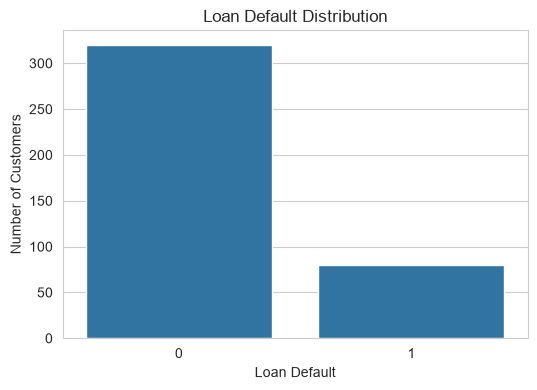

In [18]:
plt.figure(figsize=(6, 4))

sns.countplot(x="LOAN_DEFAULT", data=df)

plt.title("Loan Default Distribution")
plt.xlabel("Loan Default")
plt.ylabel("Number of Customers")

plt.show()

In [19]:
numerical_columns = df.select_dtypes(include=np.number).columns

print("Number of numerical columns:", len(numerical_columns))
print(numerical_columns.tolist())

Number of numerical columns: 35
['UNIQUEID', 'DISBURSED_AMOUNT', 'ASSET_COST', 'LTV', 'BRANCH_ID', 'SUPPLIER_ID', 'MANUFACTURER_ID', 'CURRENT_PINCODE_ID', 'STATE_ID', 'EMPLOYEE_CODE_ID', 'MOBILENO_AVL_FLAG', 'AADHAR_FLAG', 'PAN_FLAG', 'VOTERID_FLAG', 'DRIVING_FLAG', 'PASSPORT_FLAG', 'PERFORM_CNS_SCORE', 'PRI_NO_OF_ACCTS', 'PRI_ACTIVE_ACCTS', 'PRI_OVERDUE_ACCTS', 'PRI_CURRENT_BALANCE', 'PRI_SANCTIONED_AMOUNT', 'PRI_DISBURSED_AMOUNT', 'SEC_NO_OF_ACCTS', 'SEC_ACTIVE_ACCTS', 'SEC_OVERDUE_ACCTS', 'SEC_CURRENT_BALANCE', 'SEC_SANCTIONED_AMOUNT', 'SEC_DISBURSED_AMOUNT', 'PRIMARY_INSTAL_AMT', 'SEC_INSTAL_AMT', 'NEW_ACCTS_IN_LAST_SIX_MONTHS', 'DELINQUENT_ACCTS_IN_LAST_SIX_MONTHS', 'NO_OF_INQUIRIES', 'LOAN_DEFAULT']


In [20]:
categorical_columns = df.select_dtypes(include=["object"]).columns

print("Number of categorical columns:", len(categorical_columns))
print(categorical_columns.tolist())

Number of categorical columns: 6
['DATE_OF_BIRTH', 'EMPLOYMENT_TYPE', 'DISBURSAL_DATE', 'PERFORM_CNS_SCORE_DESCRIPTION', 'AVERAGE_ACCT_AGE', 'CREDIT_HISTORY_LENGTH']


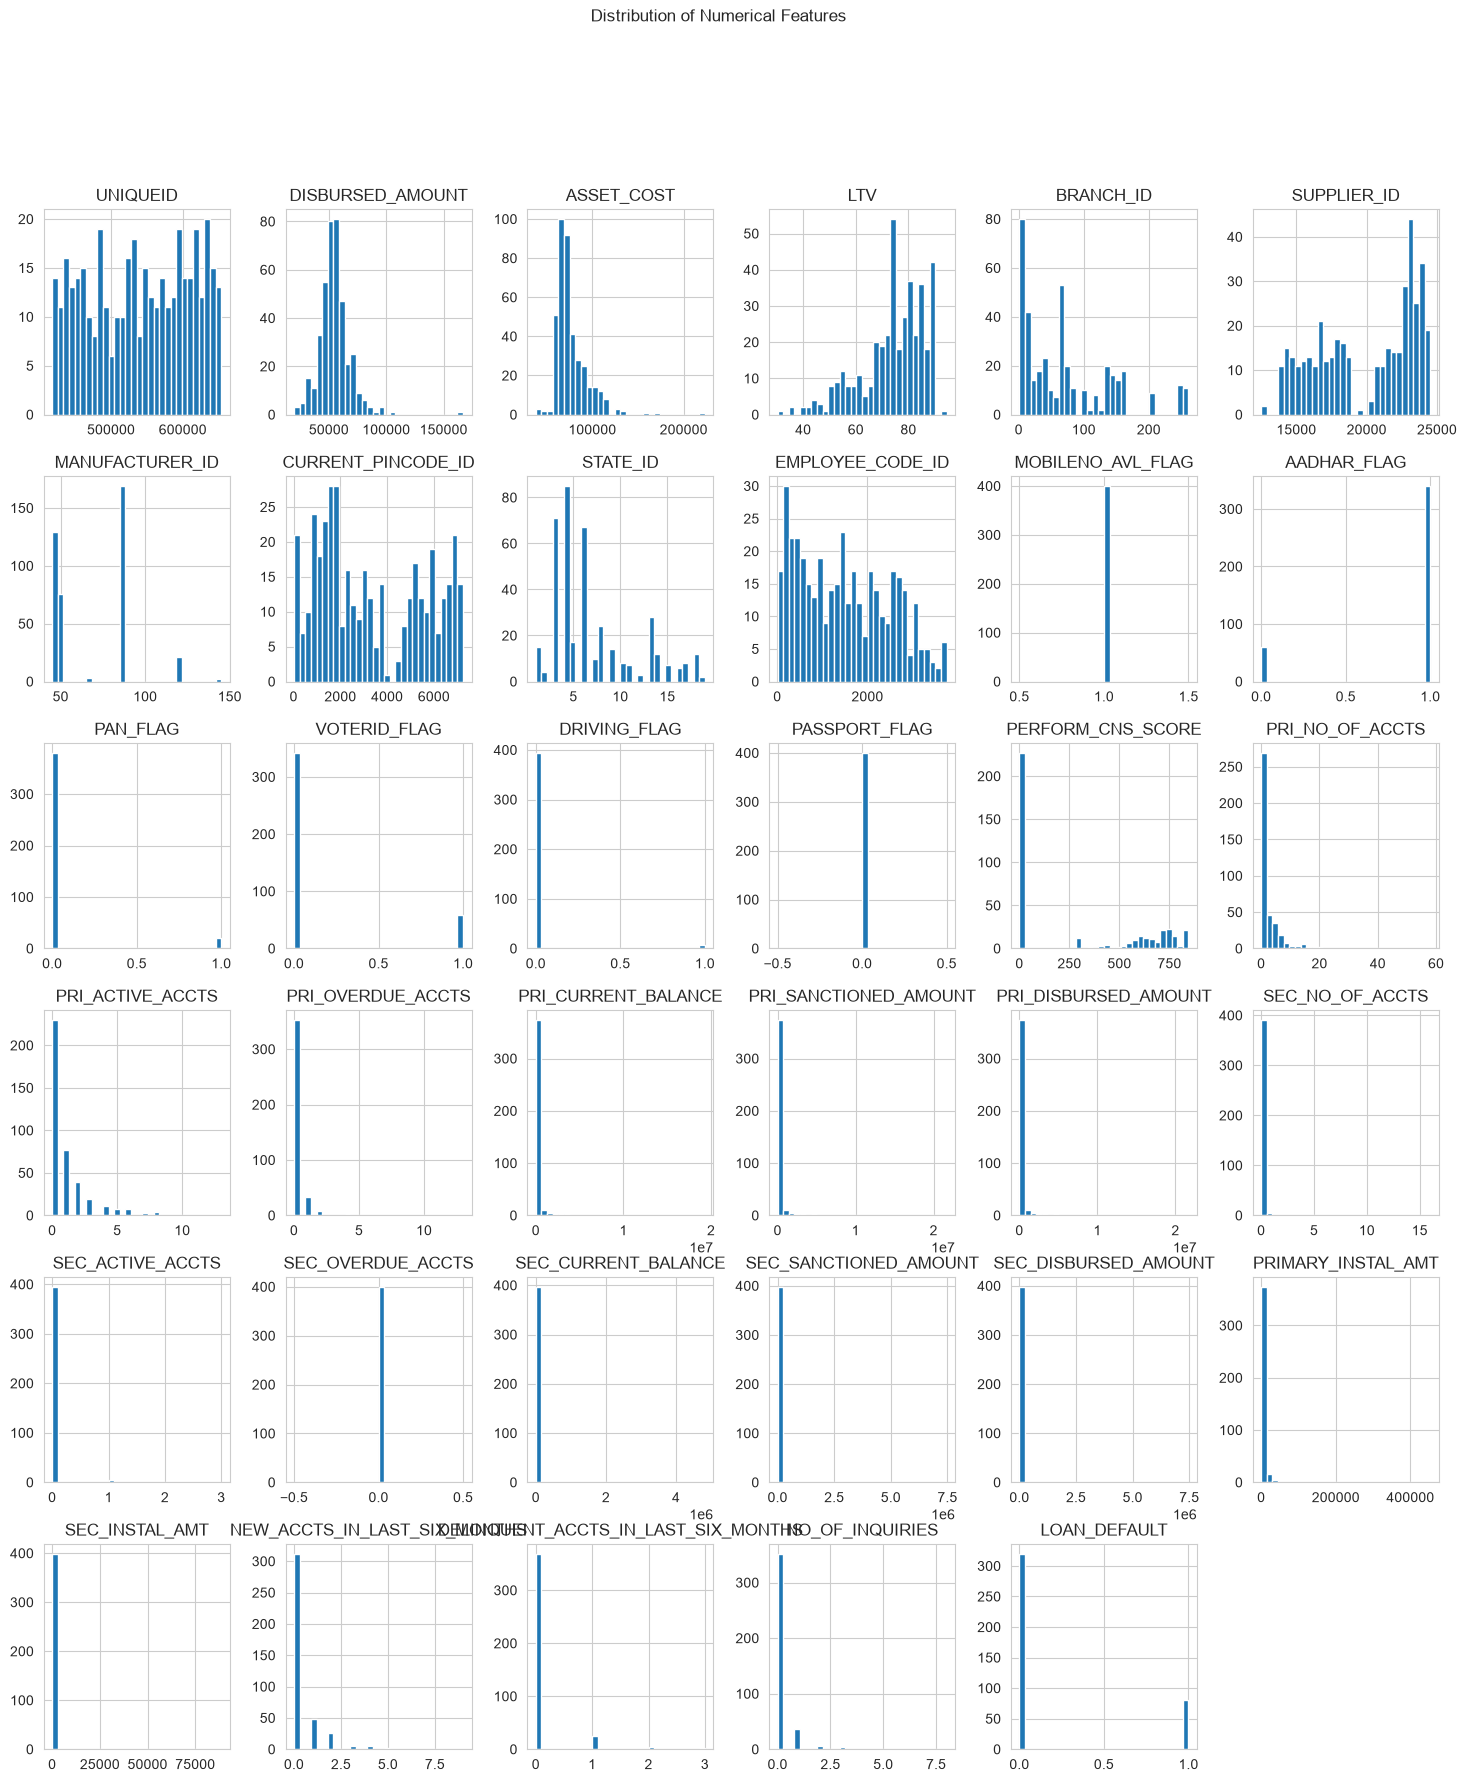

In [21]:
df[numerical_columns].hist(
    figsize=(18, 20),
    bins=30
)

plt.suptitle("Distribution of Numerical Features")

plt.show()

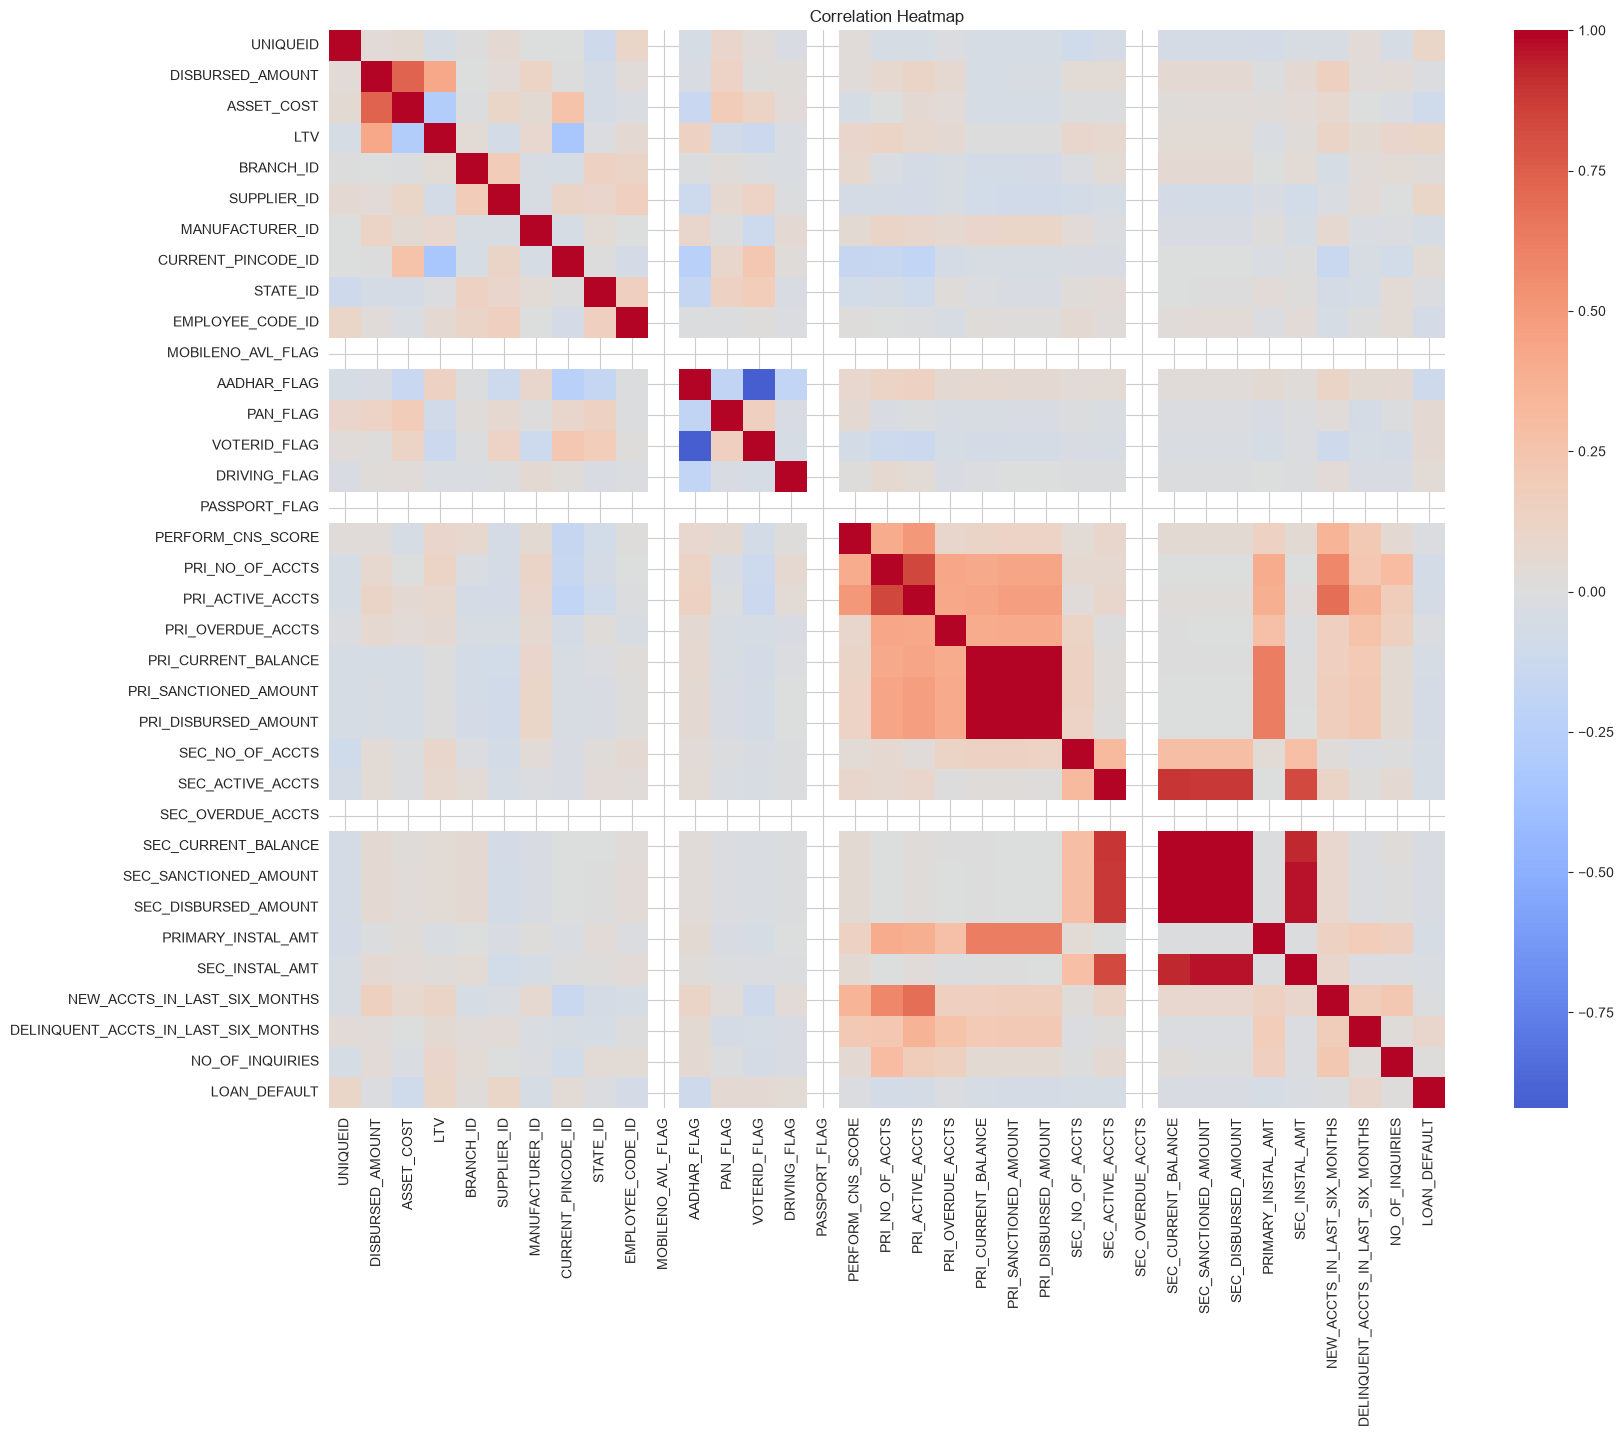

In [22]:
plt.figure(figsize=(18, 14))

correlation = df[numerical_columns].corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")

plt.show()

In [23]:
df["DATE_OF_BIRTH"] = pd.to_datetime(
    df["DATE_OF_BIRTH"],
    errors="coerce"
)

reference_date = pd.Timestamp("2018-01-01")

df["AGE"] = (
    (reference_date - df["DATE_OF_BIRTH"]).dt.days / 365.25
)

df["AGE"] = df["AGE"].abs()

In [24]:
df["DISBURSAL_DATE"] = pd.to_datetime(
    df["DISBURSAL_DATE"],
    errors="coerce"
)

df["DISBURSAL_MONTH"] = df["DISBURSAL_DATE"].dt.month

df["DISBURSAL_WEEKDAY"] = df["DISBURSAL_DATE"].dt.dayofweek

In [25]:
def convert_months(value):
    try:
        parts = str(value).split(" ")
        
        years = int(parts[0])
        months = int(parts[3])
        
        return years * 12 + months
    
    except:
        return np.nan

In [26]:
df["AVERAGE_ACCT_AGE_MONTHS"] = (
    df["AVERAGE_ACCT_AGE"].apply(convert_months)
)

df["CREDIT_HISTORY_LENGTH_MONTHS"] = (
    df["CREDIT_HISTORY_LENGTH"].apply(convert_months)
)

df[
    [
        "AGE",
        "DISBURSAL_MONTH",
        "DISBURSAL_WEEKDAY",
        "AVERAGE_ACCT_AGE_MONTHS",
        "CREDIT_HISTORY_LENGTH_MONTHS"
    ]
].head()

,AGE,DISBURSAL_MONTH,DISBURSAL_WEEKDAY,AVERAGE_ACCT_AGE_MONTHS,CREDIT_HISTORY_LENGTH_MONTHS
0,49.344285,10,3,NaN,NaN
1,41.582478,9,1,NaN,NaN
2,41.218344,8,0,NaN,NaN
3,34.231348,10,5,NaN,NaN
4,33.119781,8,4,NaN,NaN


In [27]:
drop_columns = [
    "LOAN_DEFAULT",
    "UNIQUEID",
    "DATE_OF_BIRTH",
    "DISBURSAL_DATE",
    "AVERAGE_ACCT_AGE",
    "CREDIT_HISTORY_LENGTH"
]

X = df.drop(
    columns=drop_columns,
    errors="ignore"
)

y = df["LOAN_DEFAULT"]

In [28]:
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget classes:")
print(y.value_counts())

X shape: (400, 40)
y shape: (400,)

Target classes:
LOAN_DEFAULT
0    320
1     80
Name: count, dtype: int64


In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (320, 40)
Testing data: (80, 40)


In [30]:
numerical_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['DISBURSED_AMOUNT', 'ASSET_COST', 'LTV', 'BRANCH_ID', 'SUPPLIER_ID', 'MANUFACTURER_ID', 'CURRENT_PINCODE_ID', 'STATE_ID', 'EMPLOYEE_CODE_ID', 'MOBILENO_AVL_FLAG', 'AADHAR_FLAG', 'PAN_FLAG', 'VOTERID_FLAG', 'DRIVING_FLAG', 'PASSPORT_FLAG', 'PERFORM_CNS_SCORE', 'PRI_NO_OF_ACCTS', 'PRI_ACTIVE_ACCTS', 'PRI_OVERDUE_ACCTS', 'PRI_CURRENT_BALANCE', 'PRI_SANCTIONED_AMOUNT', 'PRI_DISBURSED_AMOUNT', 'SEC_NO_OF_ACCTS', 'SEC_ACTIVE_ACCTS', 'SEC_OVERDUE_ACCTS', 'SEC_CURRENT_BALANCE', 'SEC_SANCTIONED_AMOUNT', 'SEC_DISBURSED_AMOUNT', 'PRIMARY_INSTAL_AMT', 'SEC_INSTAL_AMT', 'NEW_ACCTS_IN_LAST_SIX_MONTHS', 'DELINQUENT_ACCTS_IN_LAST_SIX_MONTHS', 'NO_OF_INQUIRIES', 'AGE', 'DISBURSAL_MONTH', 'DISBURSAL_WEEKDAY', 'AVERAGE_ACCT_AGE_MONTHS', 'CREDIT_HISTORY_LENGTH_MONTHS']

Categorical features:
['EMPLOYMENT_TYPE', 'PERFORM_CNS_SCORE_DESCRIPTION']


In [31]:
from sklearn.impute import SimpleImputer

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [32]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

logistic_model.fit(X_train, y_train)

logistic_pred = logistic_model.predict(X_test)

print("Logistic Regression completed.")

Logistic Regression completed.


In [33]:
knn_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            KNeighborsClassifier(n_neighbors=5)
        )
    ]
)

knn_model.fit(X_train, y_train)

knn_pred = knn_model.predict(X_test)

print("KNN completed.")

KNN completed.


In [34]:
nb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            GaussianNB()
        )
    ]
)

nb_model.fit(X_train, y_train)

nb_pred = nb_model.predict(X_test)

print("Gaussian Naive Bayes completed.")

Gaussian Naive Bayes completed.


In [35]:
dt_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            DecisionTreeClassifier(
                random_state=42
            )
        )
    ]
)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

print("Decision Tree completed.")

Decision Tree completed.


In [38]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import SGDClassifier

svm_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            SGDClassifier(
                loss="hinge",
                max_iter=1000,
                tol=1e-3,
                random_state=42
            )
        )
    ]
)

print("Starting SVM training...")

svm_model.fit(X_train, y_train)

print("SVM training completed.")

svm_pred = svm_model.predict(X_test)

print("SVM prediction completed.")

Starting SVM training...
SVM training completed.
SVM prediction completed.


In [39]:
models = {
    "Logistic Regression": logistic_model,
    "KNN": knn_model,
    "Gaussian Naive Bayes": nb_model,
    "Decision Tree": dt_model,
    "SVM": svm_model
}

predictions = {
    "Logistic Regression": logistic_pred,
    "KNN": knn_pred,
    "Gaussian Naive Bayes": nb_pred,
    "Decision Tree": dt_pred,
    "SVM": svm_pred
}

In [40]:
results = []

for name, pred in predictions.items():

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test,
            pred,
            average="weighted",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            pred,
            average="weighted",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test,
            pred,
            average="weighted",
            zero_division=0
        )
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,Weighted F1
0,Logistic Regression,0.8000,0.746154,0.8000,0.732081
1,KNN,0.7625,0.633766,0.7625,0.692199
2,Gaussian Naive Bayes,0.2500,0.638889,0.2500,0.196970
3,Decision Tree,0.7000,0.685281,0.7000,0.692308
4,SVM,0.6500,0.665591,0.6500,0.657516


In [41]:
results_df = results_df.sort_values(
    by="Weighted F1",
    ascending=False
).reset_index(drop=True)

results_df

,Model,Accuracy,Precision,Recall,Weighted F1
0,Logistic Regression,0.8000,0.746154,0.8000,0.732081
1,Decision Tree,0.7000,0.685281,0.7000,0.692308
2,KNN,0.7625,0.633766,0.7625,0.692199
3,SVM,0.6500,0.665591,0.6500,0.657516
4,Gaussian Naive Bayes,0.2500,0.638889,0.2500,0.196970


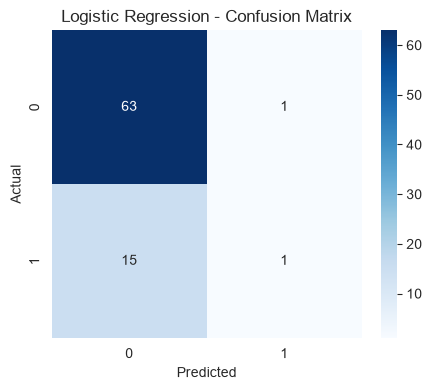

In [42]:
cm = confusion_matrix(y_test, logistic_pred)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

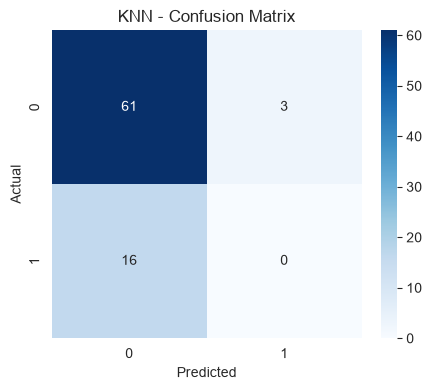

In [43]:
cm = confusion_matrix(y_test, knn_pred)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("KNN - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

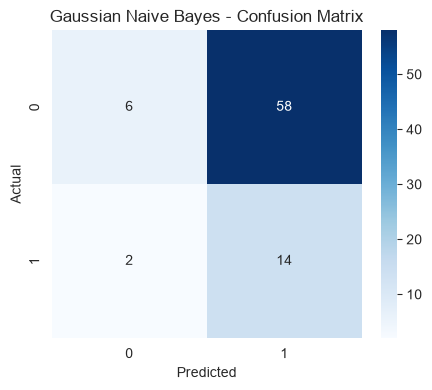

In [44]:
cm = confusion_matrix(y_test, nb_pred)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Gaussian Naive Bayes - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

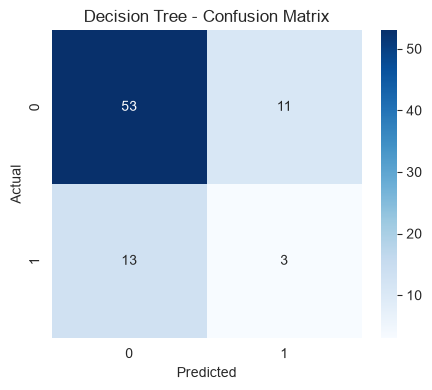

In [45]:
cm = confusion_matrix(y_test, dt_pred)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

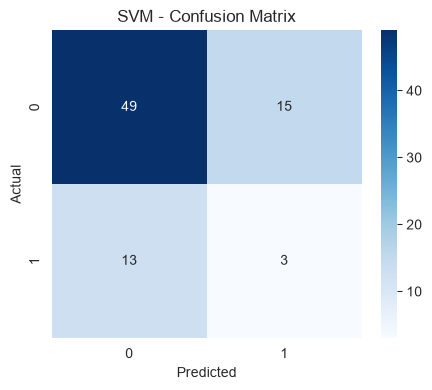

In [46]:
cm = confusion_matrix(y_test, svm_pred)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("SVM - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [47]:
for name, pred in predictions.items():

    print("=" * 70)
    print(name)
    print("=" * 70)

    print(
        classification_report(
            y_test,
            pred,
            target_names=[
                "No Default",
                "Default"
            ],
            zero_division=0
        )
    )

Logistic Regression
              precision    recall  f1-score   support

  No Default       0.81      0.98      0.89        64
     Default       0.50      0.06      0.11        16

    accuracy                           0.80        80
   macro avg       0.65      0.52      0.50        80
weighted avg       0.75      0.80      0.73        80

KNN
              precision    recall  f1-score   support

  No Default       0.79      0.95      0.87        64
     Default       0.00      0.00      0.00        16

    accuracy                           0.76        80
   macro avg       0.40      0.48      0.43        80
weighted avg       0.63      0.76      0.69        80

Gaussian Naive Bayes
              precision    recall  f1-score   support

  No Default       0.75      0.09      0.17        64
     Default       0.19      0.88      0.32        16

    accuracy                           0.25        80
   macro avg       0.47      0.48      0.24        80
weighted avg       0.64      

In [50]:
roc_results = []

for name, model in models.items():

    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_test)[:, 1]
    else:
        scores = model.decision_function(X_test)

    auc = roc_auc_score(
        y_test,
        scores
    )

    roc_results.append({
        "Model": name,
        "ROC-AUC": auc
    })

roc_df = pd.DataFrame(roc_results)

roc_df

,Model,ROC-AUC
0,Logistic Regression,0.607422
1,KNN,0.482422
2,Gaussian Naive Bayes,0.490234
3,Decision Tree,0.507812
4,SVM,0.458008


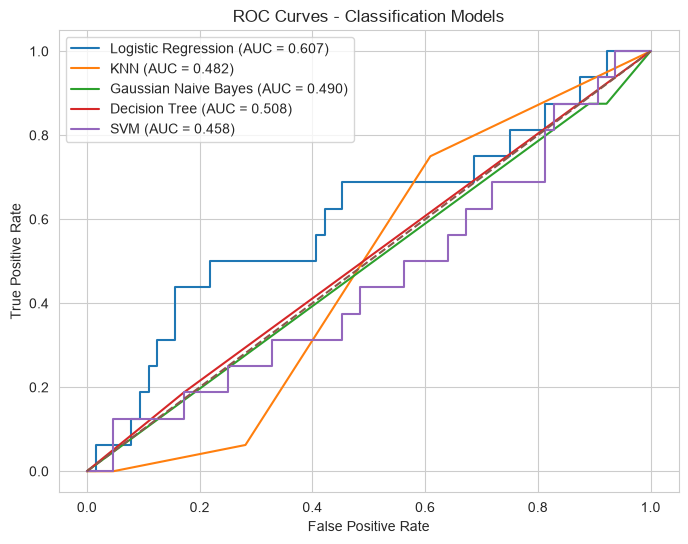

In [51]:
plt.figure(figsize=(8, 6))

for name, model in models.items():

    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_test)[:, 1]
    else:
        scores = model.decision_function(X_test)

    fpr, tpr, _ = roc_curve(
        y_test,
        scores
    )

    auc = roc_auc_score(
        y_test,
        scores
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curves - Classification Models")

plt.legend()

plt.show()

In [52]:
final_results = results_df.merge(
    roc_df,
    on="Model"
)

final_results

,Model,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
0,Logistic Regression,0.8000,0.746154,0.8000,0.732081,0.607422
1,Decision Tree,0.7000,0.685281,0.7000,0.692308,0.507812
2,KNN,0.7625,0.633766,0.7625,0.692199,0.482422
3,SVM,0.6500,0.665591,0.6500,0.657516,0.458008
4,Gaussian Naive Bayes,0.2500,0.638889,0.2500,0.196970,0.490234


In [53]:
final_results.to_csv(
    "classification_results.csv",
    index=False
)

print("Results saved successfully.")

Results saved successfully.
